In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

root = "./hit"
df = pd.read_csv(f"{root}/all_dfs.csv")
idock_df = pd.read_csv(f"{root}/tau_iface_idockq_results.csv")
print(f"n_df:{len(df)}, n_idockq:{len(idock_df)}")
# merge
merged_df = pd.merge(df, idock_df, on=["dataset", "pdb", "tau", "cluster_id", "seed"], how="left")
merged_df = merged_df[merged_df["idockq"].notnull()]
print(merged_df.columns)
for subset in merged_df["dataset"].unique():
    print(f"{subset}: {merged_df[merged_df['dataset'] == subset]['pdb'].nunique()}")
# rename dataset
rename_mapping = {
    "AA": "Antigen-Antibody",
    "PP": "Protein-Protein",
    "dsDNA": "Protein-dsDNA",
}
merged_df["dataset"] = merged_df["dataset"].apply(lambda x: rename_mapping[x])
merged_df

n_df:26208, n_idockq:125235
Index(['dataset', 'json_f', 'seed', 'tau', 'pdb', 'hit', 'cluster_id',
       'hit%_within_iface', 'num_iface_spots', 'is_hit', 'name', 'cif_path',
       'idockq', 'ranking_score'],
      dtype='str')
AA: 27
dsDNA: 14
PP: 20


,dataset,json_f,seed,tau,pdb,hit,cluster_id,hit%_within_iface,num_iface_spots,is_hit,name,cif_path,idockq,ranking_score
0,Antigen-Antibody,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,101,0.1,7um3,5,1,0.5,10,True,7um3-cluster-1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.298379,0.866356
1,Antigen-Antibody,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,101,0.1,7um3,5,1,0.5,10,True,7um3-cluster-1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.209267,0.864891
2,Antigen-Antibody,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,101,0.1,7um3,5,1,0.5,10,True,7um3-cluster-1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.196947,0.866285
3,Antigen-Antibody,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,101,0.1,7um3,5,1,0.5,10,True,7um3-cluster-1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.100084,0.863225
4,Antigen-Antibody,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,101,0.1,7um3,5,1,0.5,10,True,7um3-cluster-1,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.189577,0.865232
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125821,Protein-Protein,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,103,0.9,7b5g,1,10,1.0,1,True,7b5g-cluster-10,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.016023,0.409590
125822,Protein-Protein,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,103,0.9,7b5g,1,10,1.0,1,True,7b5g-cluster-10,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.012270,0.328944
125823,Protein-Protein,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,103,0.9,7b5g,1,10,1.0,1,True,7b5g-cluster-10,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.017324,0.443499
125824,Protein-Protein,/mnt/ai4g_share/neogaryzhou/datasets/benchmark...,103,0.9,7b5g,1,10,1.0,1,True,7b5g-cluster-10,/mnt/ai4g_share/neogaryzhou/outputs/base_const...,0.017490,0.449386


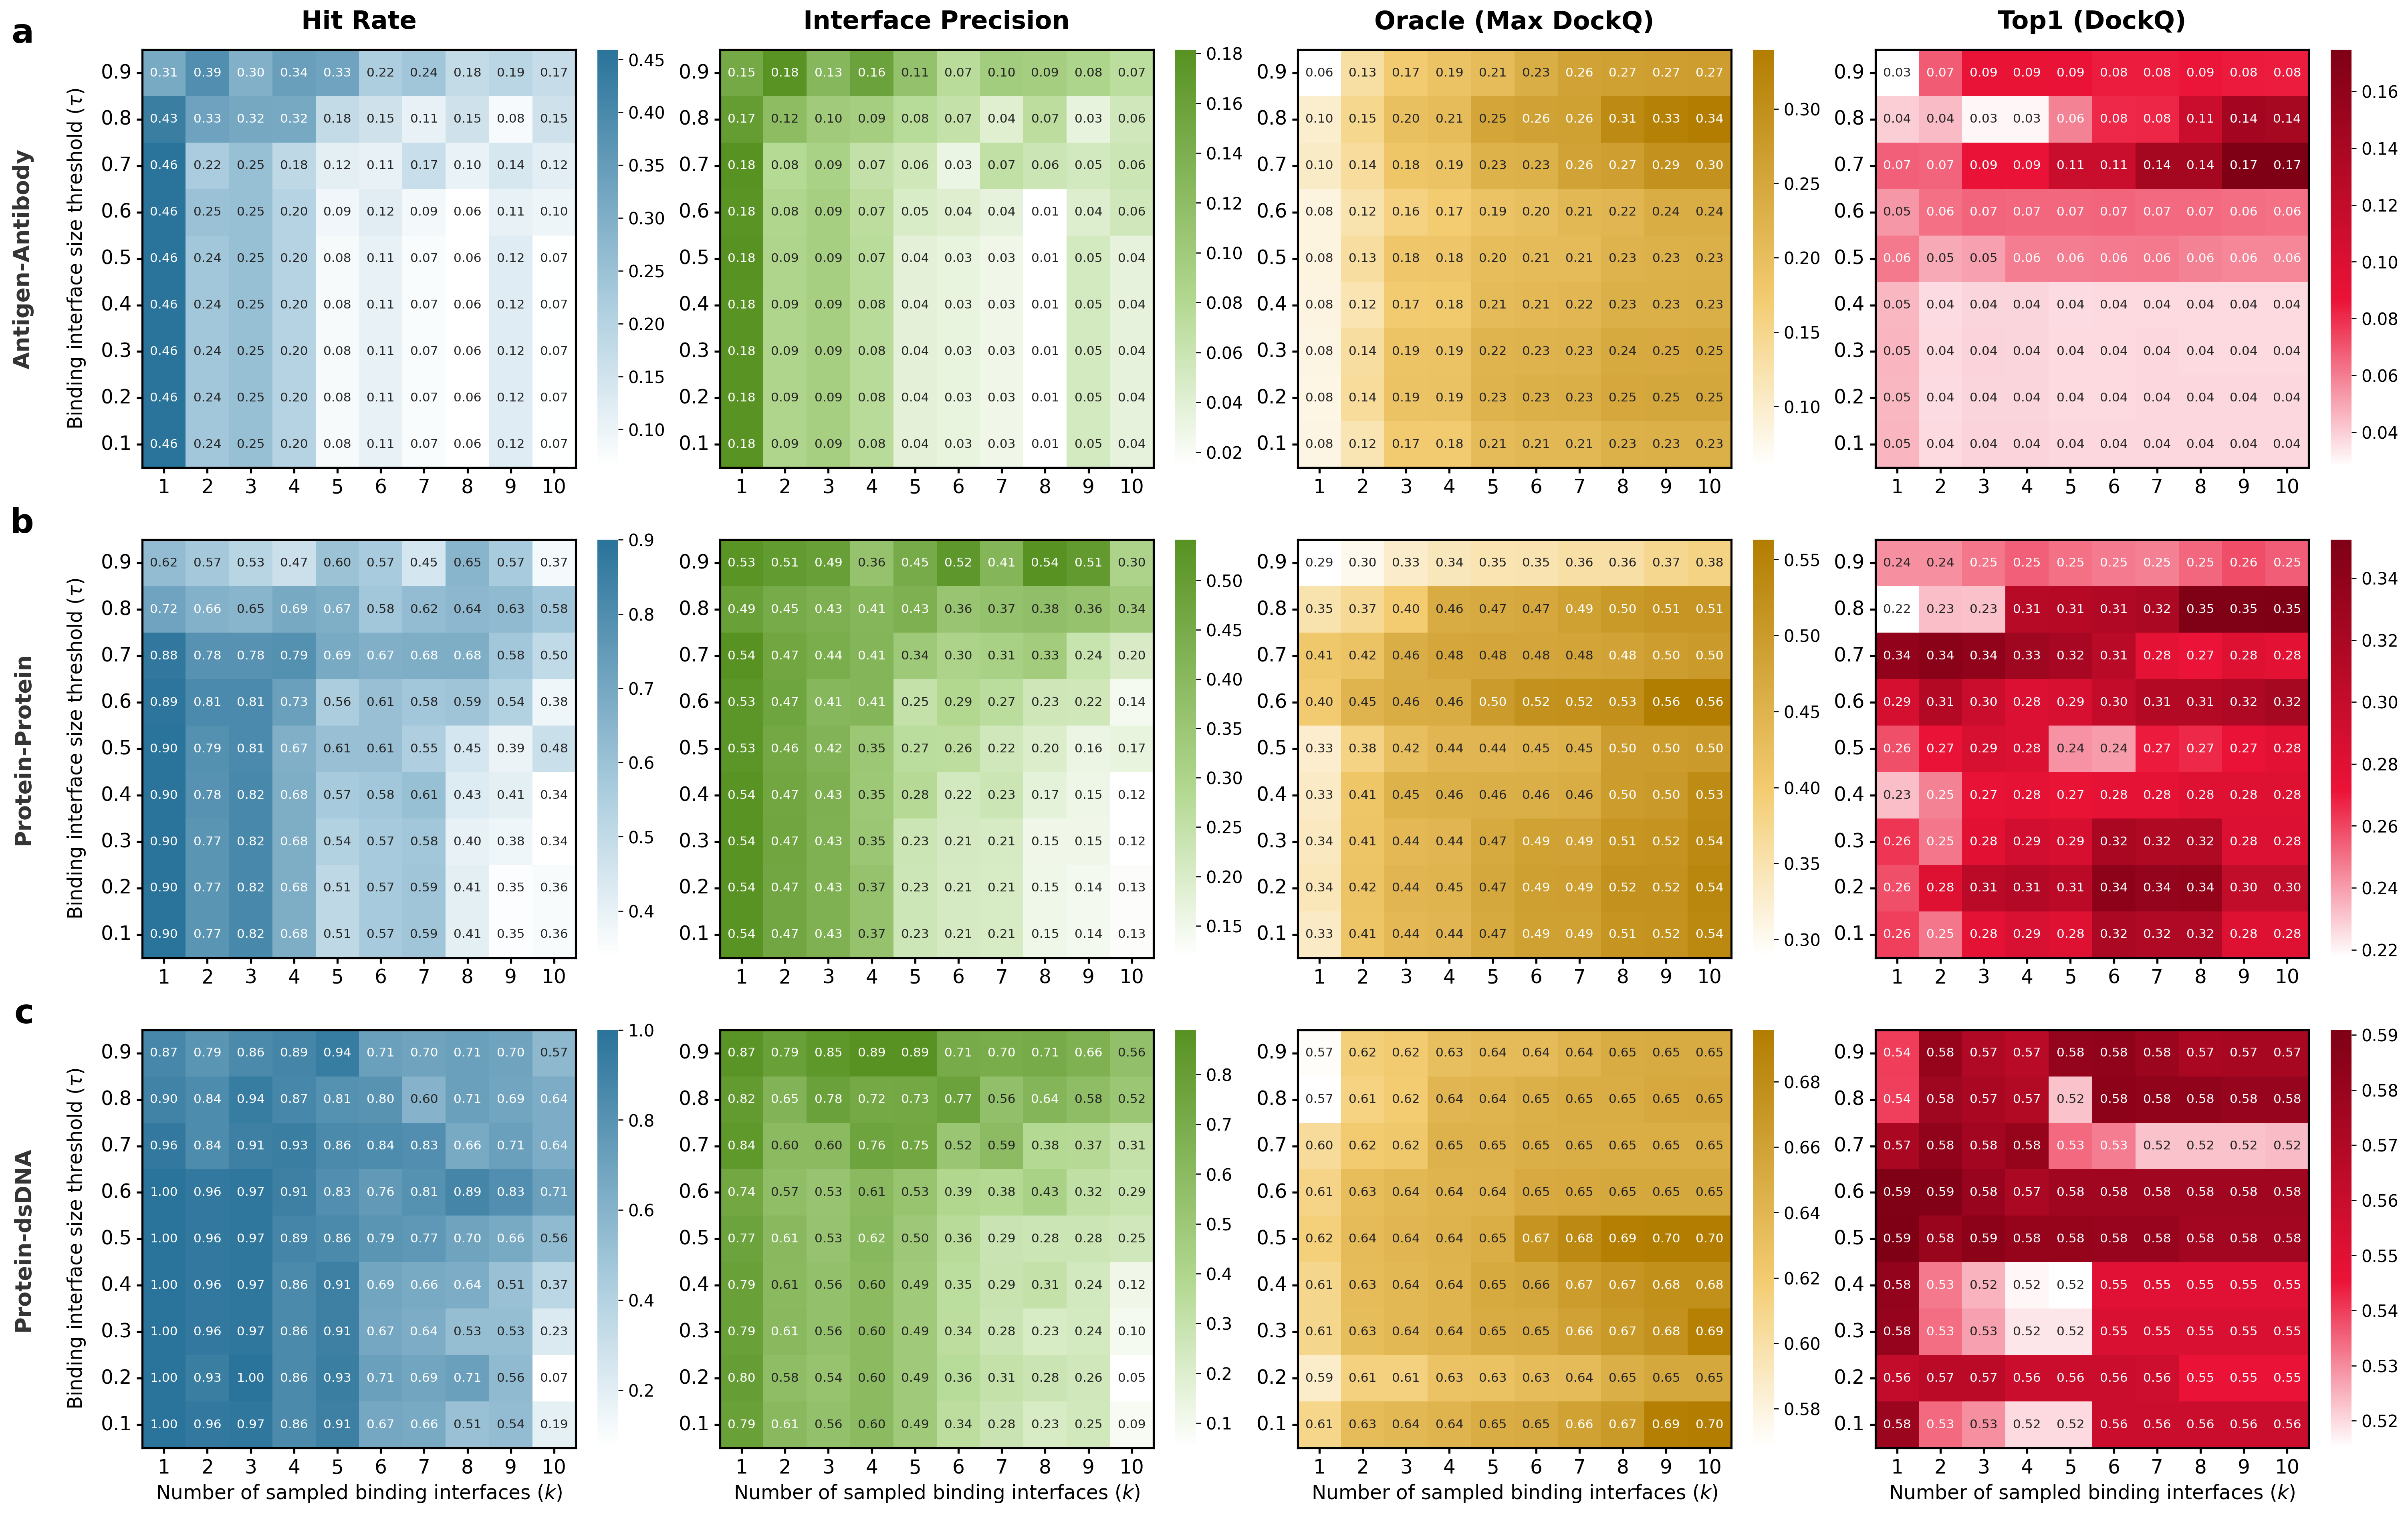

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import colorsys
import numpy as np
import string

# 假設 merged_df 已經存在
df = merged_df

# ==========================================
# 1. 字體與樣式控制中心
# ==========================================
FONT_SCALE = 1.0

FONT_CONFIG = {
    "title": int(22 * FONT_SCALE),
    "subtitle": int(18 * FONT_SCALE),
    "axis_label": int(14 * FONT_SCALE),
    "y_axis_label": int(14 * FONT_SCALE),
    "tick_label": int(14 * FONT_SCALE),
    "row_label": int(16 * FONT_SCALE),
    "cbar_label": int(12 * FONT_SCALE),
    "contour": int(10 * FONT_SCALE),
    "contour_width": 1.2 * FONT_SCALE,
    "spine_width": 1.5 * FONT_SCALE,
    "panel_label": int(24 * FONT_SCALE),
    "cell_text": int(9 * FONT_SCALE),  # 👈 新增：熱圖格子內數值的字體大小
}

# ==========================================
# 2. 配色方案設置
# ==========================================
color_dict = {
    "DynaHelix": "#eb1337",
    "Constraint with GT Iface": "#f3cc71",
    "Protenix": "#aaccde",
    "Chai-1": "#b2d890",
}


def darken_color(hex_color, darken_factor=0.5, saturate_factor=1.2):
    rgb = mcolors.hex2color(hex_color)
    h, l, s = colorsys.rgb_to_hls(*rgb)
    new_l = max(0, min(1, l * darken_factor))
    new_s = max(0, min(1, s * saturate_factor))
    new_rgb = colorsys.hls_to_rgb(h, new_l, new_s)
    return mcolors.to_hex(new_rgb)


def create_rich_cmap(base_hex):
    darker_hex = darken_color(base_hex, darken_factor=0.5, saturate_factor=1.3)
    colors = [(0.0, "#ffffff"), (0.4, base_hex), (1.0, darker_hex)]
    return mcolors.LinearSegmentedColormap.from_list("custom_rich", colors, N=256)


column_colors = [
    create_rich_cmap(color_dict["Protenix"]),
    create_rich_cmap(color_dict["Chai-1"]),
    create_rich_cmap(color_dict["Constraint with GT Iface"]),
    create_rich_cmap(color_dict["DynaHelix"]),
]


# ==========================================
# 3. 數據處理函數
# ==========================================
def prepare_pivot_data(df, label, dataset_filter=None):
    if dataset_filter is not None:
        df_filtered = df[df["dataset"] == dataset_filter].copy()
    else:
        df_filtered = df.copy()

    results = []
    for k in range(1, 11):
        if label in ["Oracle", "Top1"]:
            # Cumulative (Top-k)
            temp = df_filtered[df_filtered["cluster_id"] <= k].copy()
            if label == "Oracle":
                oracle_values = temp.groupby(["tau", "pdb"])["idockq"].max().reset_index()
                res = oracle_values.groupby("tau")["idockq"].mean().reset_index()
                res = res.rename(columns={"idockq": "Oracle"})
            elif label == "Top1":
                top1_indices = temp.groupby(["tau", "pdb"])["ranking_score"].idxmax()
                top1_data = temp.loc[top1_indices, ["tau", "pdb", "idockq"]].copy()
                res = top1_data.groupby("tau")["idockq"].mean().reset_index()
                res = res.rename(columns={"idockq": "Top1"})
        else:
            # Specific (k-th)
            temp = df_filtered[df_filtered["cluster_id"] == k].copy()
            res = temp.groupby(["tau", "pdb"])[label].mean().groupby("tau").mean().reset_index()

        res["k"] = k
        results.append(res)

    plot_df = pd.concat(results)
    pivot_df = plot_df.pivot(index="tau", columns="k", values=label)
    pivot_df = pivot_df.sort_index(ascending=True)
    return pivot_df


# ==========================================
# 4. 繪圖邏輯
# ==========================================
dataset_categories = sorted(df["dataset"].unique())
label_configs = [
    {"label": "is_hit", "label_name": "Hit Rate"},
    {"label": "hit%_within_iface", "label_name": "Interface Precision"},
    {"label": "Oracle", "label_name": "Oracle (Max DockQ)"},
    {"label": "Top1", "label_name": "Top1 (DockQ)"},
]

n_rows = len(dataset_categories)
n_cols = len(label_configs)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(6 * FONT_SCALE * n_cols, 5 * FONT_SCALE * n_rows),
    dpi=250,
    constrained_layout=True,
)

if n_rows == 1:
    axes = axes.reshape(1, -1)
elif n_cols == 1:
    axes = axes.reshape(-1, 1)

for row_idx, dataset in enumerate(dataset_categories):
    for col_idx, config in enumerate(label_configs):
        ax = axes[row_idx, col_idx]
        pivot_df = prepare_pivot_data(df, config["label"], dataset)

        # 繪製熱圖 (已修改：顯示格子內部數值)
        heatmap = sns.heatmap(
            pivot_df,
            annot=True,  # 👈 啟用格子數值顯示
            fmt=".2f",  # 👈 控制數字格式 (保留 2 位小數，可按需改為 .3f)
            annot_kws={"size": FONT_CONFIG["cell_text"]},  # 👈 控制格子字體大小
            cmap=column_colors[col_idx],
            vmin=np.min(pivot_df.values),
            vmax=np.max(pivot_df.values),
            zorder=1,
            ax=ax,
            cbar_kws={"label": ""},
        )

        cbar = heatmap.collections[0].colorbar
        cbar.ax.tick_params(labelsize=FONT_CONFIG["cbar_label"])

        # 繪製等高線
        # X, Y = np.meshgrid(np.arange(len(pivot_df.columns)) + 0.5, np.arange(len(pivot_df.index)) + 0.5)
        # contours = ax.contour(
        #     X, Y, pivot_df.values,
        #     levels=5,
        #     colors='black',
        #     linewidths=FONT_CONFIG['contour_width'],
        #     zorder=2
        # )
        # ax.clabel(contours, inline=True, fontsize=FONT_CONFIG['contour'], fmt='%.2f')

        # --- 標題設置 ---
        if row_idx == 0:
            ax.set_title(
                config["label_name"],
                pad=15,
                fontsize=FONT_CONFIG["subtitle"],
                fontweight="bold",
            )

        # --- X軸設置 ---
        if row_idx == n_rows - 1:
            xlabel_text = r"Number of sampled binding interfaces ($k$)"

            ax.set_xlabel(xlabel_text, fontsize=FONT_CONFIG["axis_label"], fontweight="normal")
        else:
            ax.set_xlabel("")

        # --- Y軸設置 ---
        ylabel_text = r"Binding interface size threshold ($\tau$)"

        if col_idx == 0:
            ax.set_ylabel(
                ylabel_text,
                fontsize=FONT_CONFIG["y_axis_label"],
                fontweight="normal",
                labelpad=10,
            )

            # Dataset 標籤
            ax.text(
                -0.25,
                0.5,
                dataset,
                transform=ax.transAxes,
                va="center",
                ha="right",
                rotation=90,
                fontsize=FONT_CONFIG["row_label"],
                fontweight="bold",
                color="#333333",
            )

            # Nature 風格 Panel 標籤 (a, b, c...)
            panel_label = string.ascii_lowercase[row_idx]
            ax.text(
                -0.25,
                1.0,
                panel_label,
                transform=ax.transAxes,
                va="bottom",
                ha="right",
                fontsize=FONT_CONFIG["panel_label"],
                fontweight="bold",
                color="black",
            )
        else:
            ax.set_ylabel(
                "",
                fontsize=FONT_CONFIG["y_axis_label"],
                fontweight="normal",
                labelpad=10,
            )

        ax.invert_yaxis()

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color("black")
            spine.set_linewidth(FONT_CONFIG["spine_width"])

        ax.tick_params(
            left=True,
            bottom=True,
            direction="out",
            length=4 * FONT_SCALE,
            width=FONT_CONFIG["spine_width"],
            colors="black",
            labelsize=FONT_CONFIG["tick_label"],
        )

        ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.savefig("./figs/fig3.pdf", format="pdf", bbox_inches="tight", dpi=300)
plt.show()

In [3]:
prepare_pivot_data(merged_df, "Top1", "Antigen-Antibody")

k,1,2,3,4,5,6,7,8,9,10
tau,,,,,,,,,,
0.1,0.046376,0.037137,0.038746,0.038807,0.037441,0.037441,0.037853,0.037853,0.037853,0.037853
0.2,0.045654,0.036651,0.038267,0.038330,0.036963,0.036963,0.037374,0.037327,0.037327,0.037327
0.3,0.046222,0.037247,0.038847,0.038269,0.036915,0.036915,0.037326,0.037252,0.037252,0.037252
0.4,0.045803,0.036633,0.037899,0.037961,0.036588,0.036795,0.037204,0.037204,0.037204,0.037204
0.5,0.061163,0.049280,0.051598,0.059939,0.059942,0.060810,0.061209,0.058992,0.057585,0.057531
0.6,0.053939,0.063177,0.066159,0.065607,0.065854,0.066344,0.065251,0.065240,0.063784,0.063736
0.7,0.067487,0.066377,0.087172,0.087021,0.114099,0.114305,0.143540,0.143382,0.174681,0.174647
0.8,0.039696,0.044267,0.029891,0.030022,0.058752,0.081218,0.081916,0.113121,0.144507,0.143020
0.9,0.027540,0.068740,0.088846,0.087953,0.087508,0.083953,0.084406,0.085626,0.084576,0.084028
